# Comparação em validação: taxa global, Poisson e NB2

Na partição de **validação**, é comparada a capacidade de três candidatos de prever o número de sinistros por apólice. A taxa global do treino é usada como referência para medir o ganho das regressões de Poisson e binomial negativa NB2. Os resultados foram gerados pelo comando `python -m freq_sinistros compare`. Ao executar o notebook, suas origens são verificadas antes da exibição das tabelas e dos gráficos. A decisão final do modelo é registrada na etapa 4, e a partição de teste é reservada para a etapa 5.

In [1]:
%matplotlib inline
from matplotlib_inline.backend_inline import set_matplotlib_formats
set_matplotlib_formats("retina")
import pandas as pd
from IPython.display import display

from freq_sinistros import artifacts, plots

LANG = "pt_br"
ROOT = artifacts.project_root()
pd.options.display.float_format = "{:,.5f}".format
pd.options.display.max_columns = 30
FULL = "train_full"

## 1. Origem dos resultados

**Pergunta.** Os resultados exibidos derivam do arquivo, das partições e do protocolo aprovados?

**Onde os modelos foram ajustados.** Os ajustes e a avaliação em validação foram executados no terminal, a partir da raiz do projeto, com `python -I -m freq_sinistros --root . compare`. As métricas, os registros de ajuste e os parâmetros do pré-processamento foram gravados em `outputs/etapa_03/`. Ao executar este notebook, a origem dos resultados é conferida e as saídas já gravadas são usadas para exibir tabelas e gráficos. Nenhum modelo é reajustado nesta leitura.

**Como a tabela analítica foi montada.** Para o Poisson e o NB2, foi construída em memória uma matriz numérica a partir da própria base, com uma linha por apólice. No treino completo, a matriz teve **474.581 linhas e 68 colunas**, incluindo o intercepto. Foram aplicadas três transformações às oito covariáveis do cenário principal.

- Área, potência, marca, combustível e região foram codificados em colunas indicadoras de 0 e 1, com agrupamento de categorias raras.
- Idade do veículo e idade do condutor foram convertidas em faixas por quantis.
- A densidade populacional foi transformada em log e padronizada.

As categorias, os cortes e os parâmetros de padronização foram aprendidos no treino de cada ajuste e reaplicados na validação. `ClaimNb` foi usado como alvo, `Exposure` como offset e `IDpol` como identificador de rastreabilidade. A taxa global foi calculada diretamente dividindo o total de sinistros pelo total de exposição do treino. [Parâmetros do pré-processamento no treino completo](../../outputs/etapa_03/preprocessing_ntrain_full.json).

In [2]:
origin = artifacts.verify_origin(ROOT)
display(pd.Series(origin["checks"], name="ok"))
out = artifacts.load_outputs(ROOT)
display(pd.Series({"arff_sha256": origin["arff_sha256"],
                   "assignment_sha256": origin["assignment_sha256"],
                   "all_ok": origin["all_ok"]}))

arff_sha256_matches_stage1_manifest      True
arff_sha256_matches_comparison           True
assignments_match_stage2_config          True
assignment_file_hash_matches             True
protocol_amendment_matches_comparison    True
stage2_validation_totals_match           True
test_partition_not_returned              True
Name: ok, dtype: bool

arff_sha256          a45363e056e2ea56408b38eeb9d4d04d7f6c6982eb7a14...
assignment_sha256    f14f53509d63ff468f025fd43096a5c2d12ba3fdd48529...
all_ok                                                            True
dtype: object

### Insights

Todas as verificações de origem foram satisfeitas: o SHA-256 do ARFF confere com o manifesto da aquisição, as atribuições coincidem com a configuração da etapa 2, a emenda ao protocolo é a mesma registrada antes do primeiro ajuste em validação, e nenhuma linha de teste é devolvida pelo carregador nem usada. O ARFF integral é interpretado em memória, mas só as partições de treino e validação são mantidas. A população de avaliação tem 101.573 registros de validação, 53.590,05 apólices-ano, 5.368 sinistros observados e 96.496 zeros.

## 2. Método

**Pergunta.** O que distingue os três candidatos e como foi feita a comparação?

Em todos os candidatos foi prevista a contagem esperada de sinistros (`ClaimNb`) para o período coberto por cada apólice (`Exposure`, em anos). Na tabela, essa contagem esperada é representada por `μ`.

| Candidato | Como a previsão é calculada | O que é representado |
| --- | --- | --- |
| `global` — taxa global | A taxa é calculada dividindo-se o total de sinistros pela soma das exposições no treino. Em seguida, é multiplicada pela exposição de cada apólice. | Uma única taxa anual é aplicada a toda a carteira, sem covariáveis. É a referência da comparação. |
| `poisson` — regressão de Poisson | É estimada uma taxa anual `exp(x′β)` a partir das covariáveis da apólice. A média é `μ = Exposure · exp(x′β)`. | A taxa varia por perfil e a variância da contagem, para um dado perfil e exposição, é igual a `μ`. |
| `nb2` — regressão binomial negativa NB2 | É usada a mesma forma para a média do Poisson, com coeficientes próprios. É estimado também o parâmetro de dispersão `α`. | A variância é `μ + αμ²`. Com `α > 0`, é acomodada uma variabilidade maior que a média mesmo após o ajuste pelas covariáveis. |

Para a média do Poisson e do NB2, foi usada a estrutura dos **modelos lineares generalizados (GLM) com ligação log**. Na fórmula, `x` reúne as covariáveis da apólice e `β` representa os coeficientes estimados. Na comparação principal, `log(Exposure)` foi incluído como **offset**, um termo com coeficiente fixado em 1. Na prática, para um mesmo perfil, dobrar o tempo de cobertura dobra a contagem esperada. A taxa global aplica essa mesma proporcionalidade ao multiplicar a taxa única pela exposição (Cameron & Trivedi, 2013).

**Implementação em Python.** Os três estimadores foram implementados em `freq_sinistros.models`. No Poisson, os coeficientes foram estimados por mínimos quadrados ponderados iterativos (IRLS), uma forma de obter o ajuste de máxima verossimilhança. No NB2, o ajuste de `β` por IRLS foi alternado com a otimização de `α` por máxima verossimilhança, com convergência conjunta verificada pelo escore (Cameron & Trivedi, 2013). Foi usado NumPy para a álgebra linear e SciPy para a otimização de `α`. O ajuste de Poisson também foi conferido contra `statsmodels.GLM`.

**Protocolo de comparação.** Em cada degrau, as mesmas linhas de treino foram usadas para os três candidatos, e o pré-processamento foi ajustado apenas nessas linhas. Foram executados os degraus aninhados de 100 mil, 200 mil e do treino inteiro, com limites de 600 s e 8 GiB por ajuste. Na validação, a métrica primária foi o desvio médio de Poisson por registro, complementado pela log-verossimilhança preditiva média e pela calibração por segmento. Foram calculados intervalos percentílicos de 95% com 1.000 réplicas bootstrap pareadas por `IDpol`, mantendo os modelos fixos.

## 3. Convergência, custo e dispersão

**Pergunta.** Os ajustes convergiram dentro dos limites, e há dispersão condicional após ajustar por perfil e exposição?

Na tabela de ajustes, **`context` identifica o cenário em que o ajuste foi executado**. O estimador é indicado por `candidato` (`candidate` no CSV), o tamanho planejado pelo degrau (`degree`) e o número de registros efetivamente usados por `n_fit`. Uma linha com degrau `100000`, `context = main` e candidato `poisson`, por exemplo, corresponde ao Poisson ajustado com 100 mil registros no cenário principal.

| Valor de `context` | Cenário de ajuste |
| --- | --- |
| `main` | Foi usada a partição principal por `IDpol`, com as contagens e exposições originais. O Poisson e o NB2 foram ajustados sem `BonusMalus` e com offset fixo. |
| `sens_bonus_malus` | Foi acrescentada a variável `BonusMalus` às regressões para medir a sensibilidade dos resultados à sua inclusão. |
| `sens_clipped_fit` | Foram aplicados os limites de 4 sinistros e 1 ano de exposição somente no ajuste. Na validação, os valores originais foram mantidos. |
| `diagnostic_free_exposure` | Foi ajustado um Poisson com coeficiente livre para `log(Exposure)` para examinar a hipótese de proporcionalidade. Ele aparece como `poisson_free_exposure` na coluna `candidato`. |
| `sens_grouped_partition` | Treino e validação foram reparticionados por perfis de covariáveis, de modo que cada perfil fosse mantido em um único lado. Os ajustes e a avaliação foram feitos nessa divisão alternativa. |

,degrau,context,candidato,n_fit,convergiu,iterações,tempo (s),pico RAM (MiB),alpha,alpha_at_poisson_limit,within_limits
0,100000,main,global,100000,True,0,0.00600,210.30000,NaN,NaN,True
1,100000,main,poisson,100000,True,5,0.30600,264.20000,NaN,NaN,True
2,100000,main,nb2,100000,True,3,1.12900,265.50000,1.28648,False,True
3,200000,main,global,200000,True,0,0.01000,295.50000,NaN,NaN,True
4,200000,main,poisson,200000,True,5,0.71300,406.90000,NaN,NaN,True
5,200000,main,nb2,200000,True,3,2.75000,408.50000,1.24613,False,True
6,train_full,main,global,474581,True,0,0.04000,454.10000,NaN,NaN,True
7,train_full,main,poisson,474581,True,5,1.75100,699.00000,NaN,NaN,True
8,train_full,main,nb2,474581,True,3,7.59100,702.60000,1.24882,False,True
9,train_full,sens_bonus_malus,global,474581,True,0,0.03400,459.30000,NaN,NaN,True


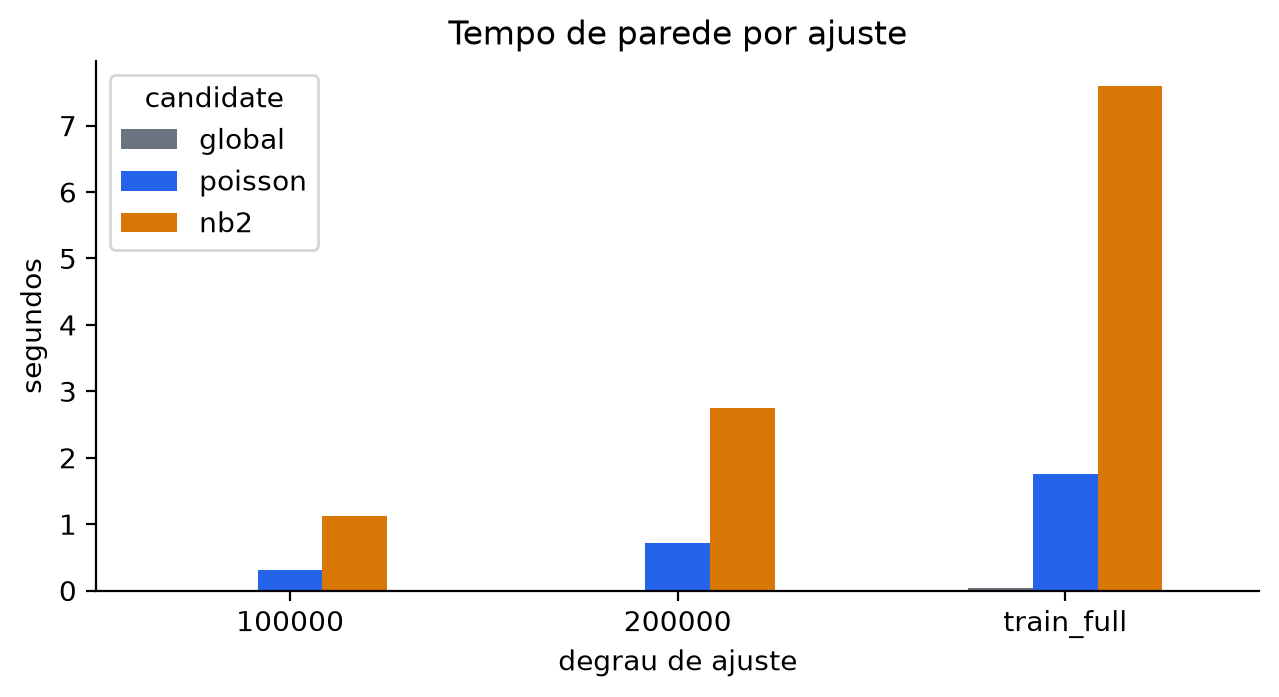

,degrau,population_rows,parameters,degrees_of_freedom,pearson_chi2,pearson_dispersion_phi,cameron_trivedi_alpha,cameron_trivedi_se_hc0,cameron_trivedi_t
0,100000,100000,64,99936,"260,284.71672",2.60451,1.17365,0.31946,3.67383
1,200000,200000,68,199932,"495,342.80470",2.47756,0.97111,0.16464,5.89828
2,train_full,474581,68,474513,"1,136,784.21142",2.39569,0.97782,0.13771,7.10072


In [3]:
fits = out["fits"]
cols = ["degree", "context", "candidate", "n_fit", "converged",
        "iterations", "wall_s", "peak_rss_mib", "alpha",
        "alpha_at_poisson_limit", "within_limits"]
display(artifacts.localize(fits[cols], LANG))
plots.show(plots.plot_cost(fits, LANG))
display(artifacts.localize(out["dispersion_diagnostics"], LANG))

### Insights

Todos os ajustes principais e de sensibilidade convergiram e couberam nos limites; o maior degrau viável é o treino inteiro, e os três degraus foram verificados. No treino inteiro, o Poisson levou 1,8 s e o NB2, 7,6 s; o pico de memória do ajuste NB2 foi de 703 MiB, e o do processo completo de `compare`, de 1.019 MiB (ajuste de diagnóstico com `log(Exposure)` livre). Tempos e picos são os de `fits.csv` e `cost.json`, da mesma execução que gerou as demais tabelas. A dispersão estimada do NB2 foi `α = 1,249`, longe do limite de Poisson (`α → 0`), e o escore no ótimo foi desprezível (abaixo de 1e-6 por linha). Para o diagnóstico condicional, a população é o Poisson ajustado nas 474.581 linhas do degrau, com 474.513 graus de liberdade. A estatística de Pearson dividida pelos graus de liberdade foi 2,40. O estimador de Cameron e Trivedi (1990) para `α` foi 0,978 (estatística t robusta 7,1), em linha com a dispersão acima de 1. A estatística de Pearson pode ser sensível a linhas com média prevista muito pequena, de modo que o valor deve ser lido junto ao estimador de `α`.

## 4. Métricas em validação

**Pergunta.** Qual candidato prediz melhor as contagens em validação, e as diferenças são distinguíveis da variabilidade da amostra?

,degrau,candidato,registros,exposição,sinistros observados,sinistros previstos,observed_rate_per_100,predicted_rate_per_100,taxa prevista − observada,desvio médio de Poisson,log-verossimilhança média
0,100000,global,101573,"53,590.04868",5368,"5,297.63155",10.01679,9.88548,-0.13131,0.32863,-0.21515
1,100000,poisson,101573,"53,590.04868",5368,"5,291.96004",10.01679,9.87489,-0.14189,0.31975,-0.21071
2,100000,nb2,101573,"53,590.04868",5368,"5,401.80836",10.01679,10.07987,0.06309,0.31987,-0.20995
3,200000,global,101573,"53,590.04868",5368,"5,362.83835",10.01679,10.00715,-0.00963,0.32862,-0.21514
4,200000,poisson,101573,"53,590.04868",5368,"5,357.50625",10.01679,9.99720,-0.01958,0.31920,-0.21043
5,200000,nb2,101573,"53,590.04868",5368,"5,462.61129",10.01679,10.19333,0.17655,0.31930,-0.20968
6,train_full,global,101573,"53,590.04868",5368,"5,404.24902",10.01679,10.08443,0.06764,0.32863,-0.21514
7,train_full,poisson,101573,"53,590.04868",5368,"5,397.13125",10.01679,10.07114,0.05436,0.31899,-0.21032
8,train_full,nb2,101573,"53,590.04868",5368,"5,506.45760",10.01679,10.27515,0.25836,0.31910,-0.20957


,indicador,estimativa,IC inf.,IC sup.
276,d_dev|poisson-global,-0.00964,-0.01111,-0.00815
277,d_ll|poisson-global,0.00482,0.00408,0.00556
278,d_dev|nb2-poisson,0.00011,0.00003,0.00019
279,d_ll|nb2-poisson,0.00075,0.00036,0.00130
280,d_dev|nb2-global,-0.00953,-0.01108,-0.00798
281,d_ll|nb2-global,0.00557,0.00475,0.00639


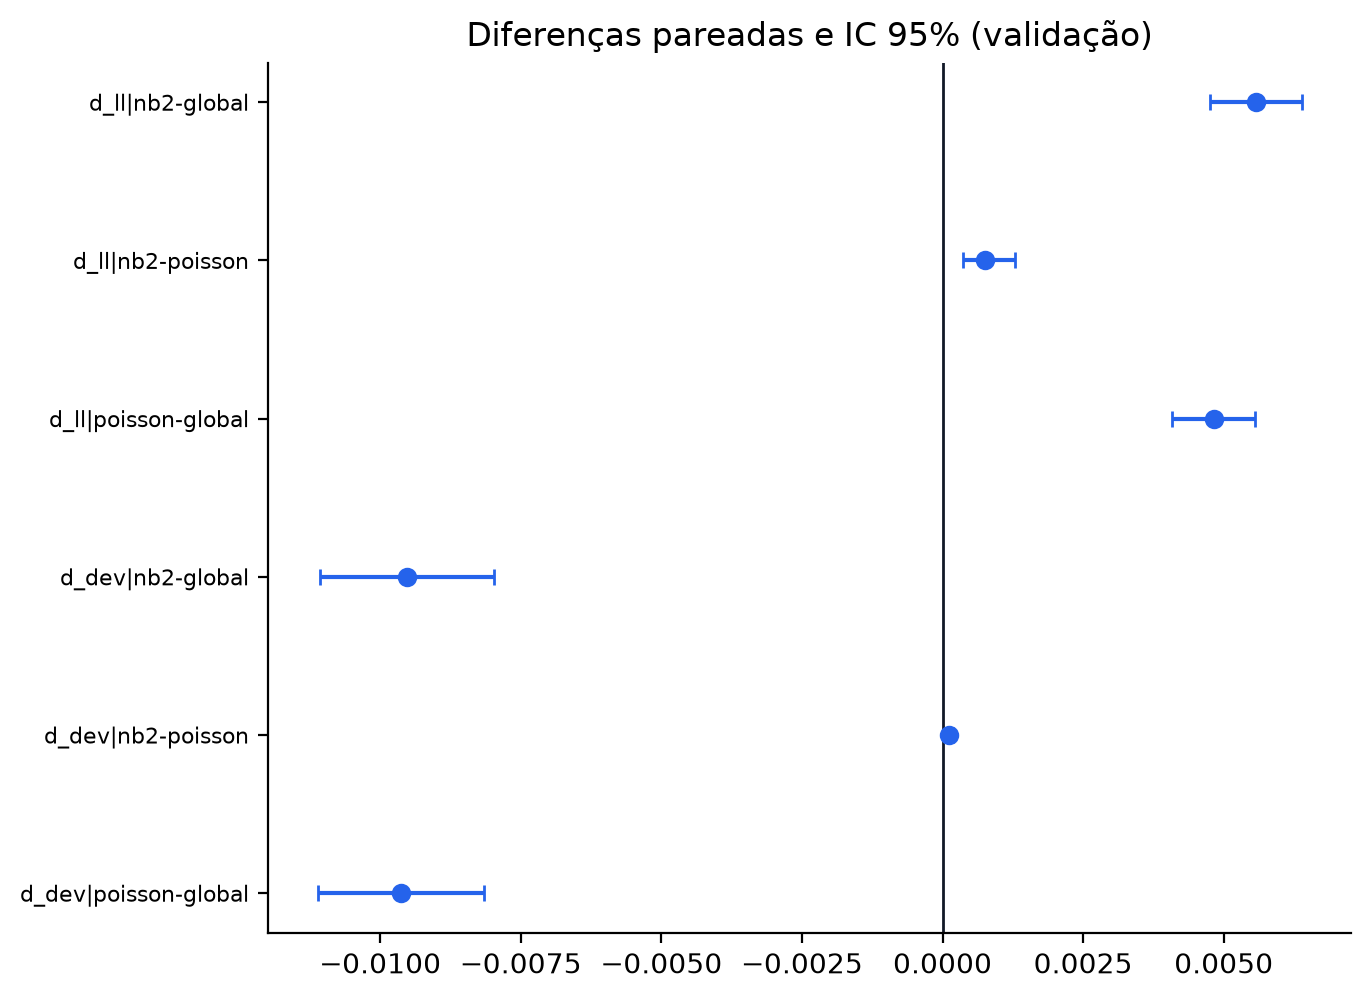

In [4]:
display(artifacts.localize(artifacts.main_metrics(out), LANG))
keys = artifacts.KEY_INDICATORS
sub = artifacts.select_intervals(out["intervals"], FULL, "validation", keys)
display(artifacts.localize(sub[["indicator", "estimate", "ci_low",
                                "ci_high"]], LANG))
plots.show(plots.plot_forest(sub, LANG, keys))

### Insights

No treino inteiro, o desvio médio de Poisson foi 0,32863 (taxa global), 0,31899 (Poisson) e 0,31910 (NB2). A diferença de desvio Poisson − taxa global é -0,00964 (IC 95% -0,01111 a -0,00815; valores negativos favorecem o Poisson); o intervalo exclui zero, e o resultado se mantém no bootstrap por perfil (-0,01112 a -0,00813). O NB2 melhora a log-verossimilhança média frente ao Poisson em 0,00075 (IC 0,00036 a 0,00130), mas seu desvio médio é maior em 0,00011 (IC 0,00003 a 0,00019), isto é, suas médias previstas são ligeiramente piores. A diferença de taxa global (prevista − observada, por 100 apólices-ano, com taxa observada de 10,02) foi 0,068 (global), 0,054 (Poisson) e 0,258 (NB2). Esses são os valores publicados, sem recalibração.

## 5. Regras de escolha (provisórias)

**Pergunta.** O que as regras do parecer indicam em cada degrau e na partição agrupada? A decisão de modelo pertence à etapa 4.

In [5]:
display(artifacts.rules_table(out))

,degree,population,poisson_over_global,nb2_over_poisson,preferred_by_rules
0,100000,validation,False,False,global
1,200000,validation,False,False,global
2,train_full,validation,True,False,poisson
3,train_full,grouped_validation,True,True,nb2


### Insights

No treino inteiro, o Poisson satisfaz as duas condições frente à taxa global (ganho de desvio com intervalo excluindo zero e erro absoluto de taxa global menor), enquanto o NB2 não satisfaz as condições frente ao Poisson, pois a melhora na log-verossimilhança vem acompanhada de desvio e de erro de taxa global maiores. A condição de calibração global do Poisson frente à taxa global não se sustenta nos degraus menores (diferenças de -0,142 contra -0,131 no degrau de 100 mil), e o ganho no desvio mantém o mesmo sinal nos três degraus. Assim, a preferência pelo Poisson é estável quanto ao desvio e instável quanto ao erro de taxa global entre degraus. Na partição agrupada, as condições do NB2 são satisfeitas, ao contrário da partição principal; o resultado depende da população de avaliação.

## 6. Calibração por segmento

**Pergunta.** Onde as taxas previstas se afastam das observadas? As diferenças são prevista − observada, por 100 apólices-ano, calculadas com a exposição total do grupo. Segmentos de baixo suporte são mostrados sem intervalo.

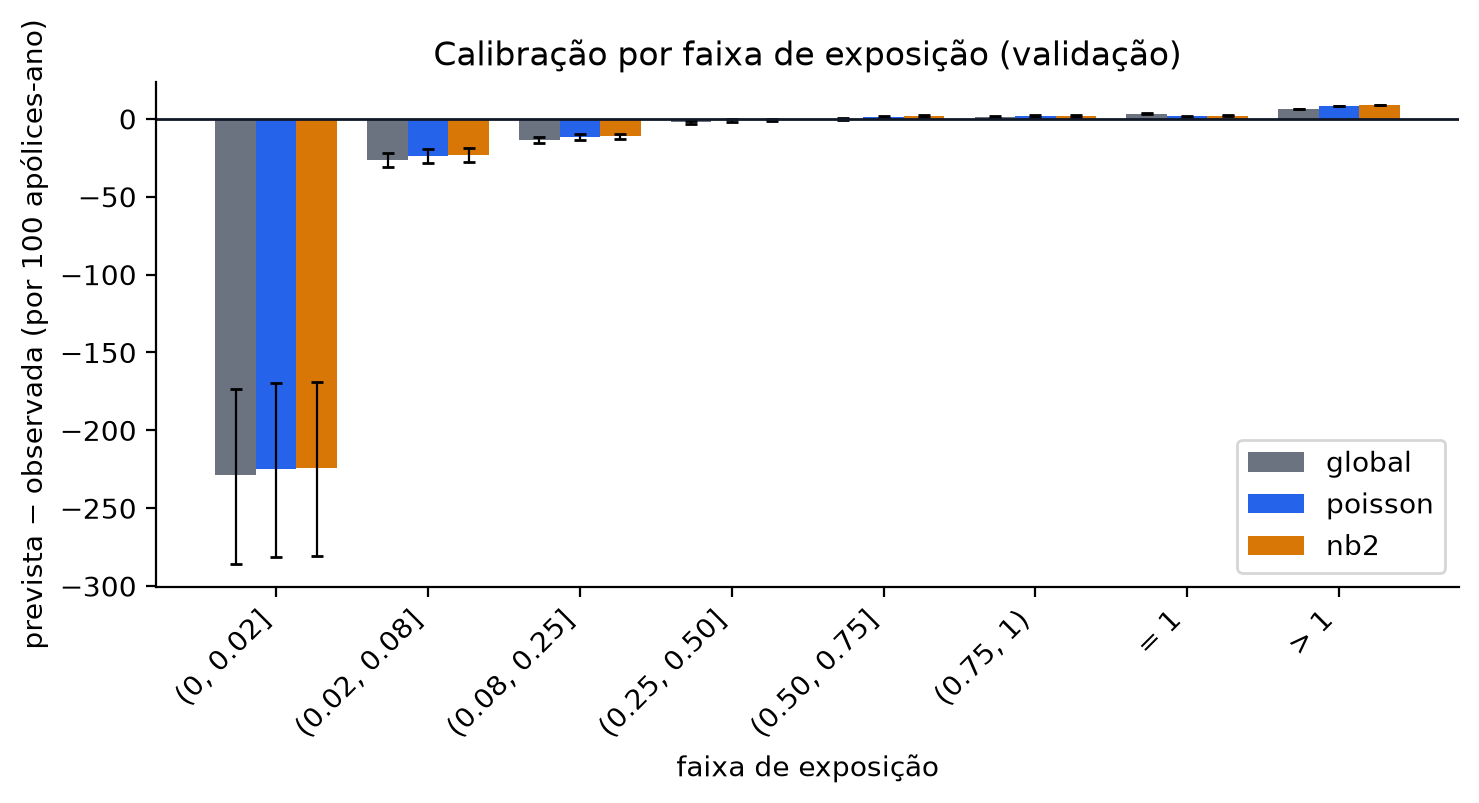

candidate,segmento,registros,observed_rate_per_100,global,nb2,poisson,baixo suporte
0,"(0, 0.02]",2873,238.99178,-228.90735,-224.16892,-224.75650,False
1,"(0.02, 0.08]",14314,36.21449,-26.13007,-23.33384,-23.76996,False
2,"(0.08, 0.25]",16322,23.68658,-13.60216,-11.24495,-11.61929,False
3,"(0.25, 0.50]",19693,12.36607,-2.28164,-0.61676,-0.92737,False
4,"(0.50, 0.75]",13882,9.97211,0.11232,1.62068,1.33238,False
5,"(0.75, 1)",9263,8.99806,1.08637,1.90992,1.66387,False
6,= 1,25042,6.90041,3.18402,1.89244,1.79464,False
7,> 1,184,3.42382,6.66061,8.92324,8.46414,True


candidate,segmento,registros,observed_rate_per_100,global,nb2,poisson,baixo suporte
0,0-1,19252,16.24647,-6.16204,1.09110,0.24249,False
1,11-20,26607,8.27068,1.81375,-0.05702,-0.16086,False
2,2-5,28595,9.30746,0.77697,0.09772,0.01579,False
3,21+,1282,5.10794,4.97648,1.49136,1.41831,False
4,6-10,25837,9.74922,0.33521,0.27246,0.14992,False


candidate,segmento,registros,observed_rate_per_100,global,nb2,poisson,baixo suporte
0,R11,10359,13.06690,-2.98248,0.47283,0.06679,False
1,R21,463,11.62422,-1.53979,2.04202,1.53969,True
2,R22,1203,14.02480,-3.94038,-1.69053,-2.00098,False
3,R23,1330,9.29700,0.78742,0.60322,0.35893,False
4,R24,24049,8.87631,1.20811,0.20046,0.06442,False
5,R25,1659,9.50664,0.57779,0.16009,0.00991,False
6,R26,1557,12.95932,-2.87490,-3.13718,-3.32187,False
7,R31,4133,10.45536,-0.37093,0.18106,-0.06997,False
8,R41,1954,8.01135,2.07307,-0.63706,-0.72960,False
9,R42,318,9.91306,0.17137,1.67925,1.53283,True


In [6]:
cal = out["calibration_by_segment"]
plots.show(plots.plot_calibration_bands(
    cal[(cal["population"] == "validation")
        & (cal["degree"].astype(str) == FULL)], LANG))
for family in ("exposure_band", "vehicle_age", "region"):
    display(artifacts.localize(
        artifacts.calibration_pivot(out, family, FULL), LANG))

### Insights

O offset com coeficiente 1 não reproduz as faixas de exposição. Em `(0; 0,02]`, a taxa observada é 239,0 e a prevista pelo Poisson, 14,2 (diferença de -224,8); em exatamente um ano, a observada é 6,90 e a prevista, 8,70. Os três candidatos subestimam as faixas curtas e superestimam as longas, como antecipado pelo diagnóstico do treino, e, para o Poisson, os intervalos excluem zero em todas as faixas com suporte. Por idade do veículo e por região, os desvios são pequenos e, em geral, os intervalos incluem zero; as regiões e a faixa `> 1` de baixo suporte são mostradas sem intervalo. Nenhuma recalibração pós-hoc foi aplicada.

## 7. Zeros previstos (resumo preliminar)

**Pergunta.** Quantos zeros são previstos, `Σ P(Y_i = 0)`, em comparação com os observados? O diagnóstico formal pertence à etapa 4.

,degrau,population,candidato,faixa,registros,zeros_observed,zeros_predicted,diff_pred_minus_obs,IC inf.,IC sup.,sensitivity
0,train_full,validation,global,overall,101573,96496,"96,374.87785",-121.12215,-247.73270,4.62598,NaN
1,train_full,validation,global,"(0, 0.02]",2873,2801,"2,869.75333",68.75333,52.71635,86.73743,NaN
2,train_full,validation,global,"(0.02, 0.08]",14314,14000,"14,221.87313",221.87313,188.28015,256.63746,NaN
3,train_full,validation,global,"(0.08, 0.25]",16322,15684,"16,040.69702",356.69702,305.68837,405.72479,NaN
4,train_full,validation,global,"(0.25, 0.50]",19693,18789,"18,930.78324",141.78324,86.40013,198.91320,NaN
5,train_full,validation,global,"(0.50, 0.75]",13882,13061,"13,024.20537",-36.79463,-88.06140,17.70137,NaN
6,train_full,validation,global,"(0.75, 1)",9263,8588,"8,483.22907",-104.77093,-149.60583,-55.98639,NaN
7,train_full,validation,global,= 1,25042,23396,"22,639.81657",-756.18343,-828.15768,-680.90865,NaN
8,train_full,validation,global,> 1,184,177,164.52011,-12.47989,NaN,NaN,NaN
9,train_full,validation,poisson,overall,101573,96496,"96,406.57327",-89.42673,-210.56669,42.96309,NaN


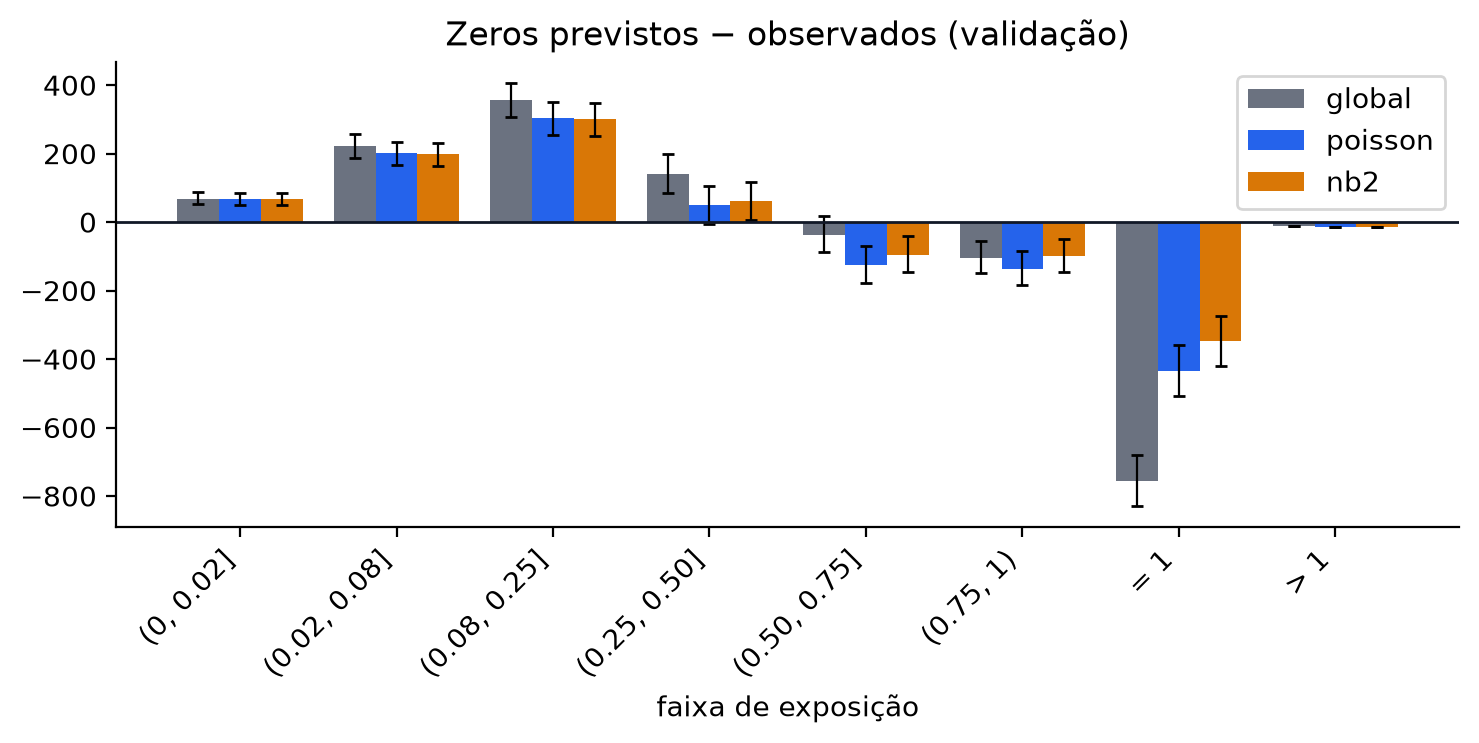

,degrau,population,candidato,faixa,registros,zeros_observed,zeros_predicted,diff_pred_minus_obs,IC inf.,IC sup.,sensitivity
0,train_full,validation_free_exposure_diagnostic,poisson_free_exposure,overall,101573,96496,"96,335.78600",-160.21400,-283.13274,-29.96932,free_exposure_diagnostic
1,train_full,validation_free_exposure_diagnostic,poisson_free_exposure,"(0, 0.02]",2873,2801,"2,830.08340",29.08340,12.92364,46.92081,free_exposure_diagnostic
2,train_full,validation_free_exposure_diagnostic,poisson_free_exposure,"(0.02, 0.08]",14314,14000,"13,921.99909",-78.00091,-110.06054,-42.85335,free_exposure_diagnostic
3,train_full,validation_free_exposure_diagnostic,poisson_free_exposure,"(0.08, 0.25]",16322,15684,"15,679.39296",-4.60704,-53.30639,42.72099,free_exposure_diagnostic
4,train_full,validation_free_exposure_diagnostic,poisson_free_exposure,"(0.25, 0.50]",19693,18789,"18,678.48024",-110.51976,-166.26589,-51.85558,free_exposure_diagnostic
5,train_full,validation_free_exposure_diagnostic,poisson_free_exposure,"(0.50, 0.75]",13882,13061,"13,032.09903",-28.90097,-79.51437,25.36896,free_exposure_diagnostic
6,train_full,validation_free_exposure_diagnostic,poisson_free_exposure,"(0.75, 1)",9263,8588,"8,642.14539",54.14539,9.05158,103.31648,free_exposure_diagnostic
7,train_full,validation_free_exposure_diagnostic,poisson_free_exposure,= 1,25042,23396,"23,381.80023",-14.19977,-85.55244,58.36725,free_exposure_diagnostic
8,train_full,validation_free_exposure_diagnostic,poisson_free_exposure,> 1,184,177,169.78566,-7.21434,NaN,NaN,free_exposure_diagnostic


In [7]:
zeros = artifacts.zero_table(out, FULL)
display(artifacts.localize(zeros, LANG))
plots.show(plots.plot_zero_diff(zeros, LANG))
diagnostic = artifacts.zero_table(
    out, FULL, "validation_free_exposure_diagnostic",
    ("poisson_free_exposure",))
display(artifacts.localize(diagnostic, LANG))

### Insights

No total, a diferença entre zeros previstos e observados é -89,4 no Poisson (IC -210,6 a 43,0) e 69,5 no NB2 (IC -52,3 a 200,7); ambos os intervalos incluem zero. Por faixa, o padrão tem sinais opostos: zeros são superestimados nas faixas curtas (por exemplo, 200,6 em `(0,02; 0,08]` no Poisson) e subestimados nas faixas longas (por exemplo, -433,7 em exatamente um ano). Isso reflete a subestimação das contagens curtas, não necessariamente um segundo processo gerador de zeros. Essa leitura vale para a taxa global, o Poisson e o NB2 com exposição proporcional. O diagnóstico exploratório com `log(Exposure)` livre (não é candidato) prevê menos zeros do que os observados: -160,2 no total (IC -283,1 a -30,0), com déficits de -78,0 em `(0,02; 0,08]` (IC -110,1 a -42,9) e de -110,5 em `(0,25; 0,50]` (IC -166,3 a -51,9), ambas faixas com suporte. Esse resultado é apresentado à parte e não satisfaz, por si, o requisito de uma hipótese plausível para um segundo processo, que permanece separado; a avaliação da inflação de zeros cabe à etapa 4.

## 8. Reconciliação

**Pergunta.** Registros, exposição, sinistros observados e previstos de cada segmentação reconciliam com os totais?

In [8]:
display(artifacts.population_totals(out))
display(artifacts.reconciliation_summary(out))

,population,records,exposure,observed_claims,candidates,checks,all_ok,reconciled_by_segment
0,validation,"101,573.00000","53,590.04868","5,368.00000",3,108,True,True
1,validation_bonus_malus,"101,573.00000","53,590.04868","5,368.00000",4,48,True,True
2,validation_clipped_fit,"101,573.00000","53,590.04868","5,368.00000",5,60,True,True
3,validation_free_exposure_diagnostic,"101,573.00000","53,590.04868","5,368.00000",3,36,True,True
4,grouped_validation,"101,676.00000","53,674.22319","5,520.00000",3,36,True,True
5,"validation (Exposure > 0.02, descriptive)","98,700.00000","53,557.83000","5,291.00000",3,0,None,False


,population,checks,all_ok
0,grouped_validation,36,True
1,validation,108,True
2,validation_bonus_malus,48,True
3,validation_clipped_fit,60,True
4,validation_free_exposure_diagnostic,36,True


### Insights

Cada população tem seus próprios denominadores. A validação principal tem 101.573 registros, 53.590,05 apólices-ano e 5.368 sinistros; a validação agrupada, 101.676 registros e 5.520 sinistros. As sensibilidades de `BonusMalus`, de limites aplicados ao ajuste e de `log(Exposure)` livre reusam a validação principal. Em todas essas populações, a soma dos segmentos de cada segmentação coincide com os totais de registros, exposição, sinistros observados e previstos de cada candidato (uma verificação por candidato, segmentação e indicador). O recorte descritivo sem a faixa `(0; 0,02]`, com 98.700 registros e 5.291 sinistros, entra apenas no resumo da métrica geral e não foi reconciliado por segmento. Os totais de registros e exposição da validação coincidem com os da etapa 2; os sinistros de validação são reconciliados aqui pela primeira vez.

## 9. Sensibilidades

**Pergunta.** Os resultados mudam com `BonusMalus`, com limites aplicados só ao ajuste, com bootstrap por perfil, com a partição agrupada ou sem a faixa muito curta? O Poisson com `log(Exposure)` livre é apenas diagnóstico.

In [9]:
display(artifacts.localize(artifacts.sensitivity_table(out), LANG))

,population,indicador,estimativa,IC inf.,IC sup.
0,validation_cluster_bootstrap,d_dev|poisson-global,-0.00964,-0.01112,-0.00813
1,validation_cluster_bootstrap,d_ll|poisson-global,0.00482,0.00407,0.00556
2,validation_cluster_bootstrap,d_dev|nb2-poisson,0.00011,0.00001,0.00020
3,validation_cluster_bootstrap,d_ll|nb2-poisson,0.00075,0.00035,0.00128
4,validation_cluster_bootstrap,d_dev|nb2-global,-0.00953,-0.01110,-0.00794
5,validation_cluster_bootstrap,d_ll|nb2-global,0.00557,0.00469,0.00642
6,validation_bonus_malus,d_dev|poisson_bonus-poisson,-0.00539,-0.00637,-0.00448
7,validation_bonus_malus,d_ll|poisson_bonus-poisson,0.00269,0.00224,0.00318
8,validation_bonus_malus,d_dev|nb2_bonus-nb2,-0.00543,-0.00642,-0.00452
9,validation_bonus_malus,d_ll|nb2_bonus-nb2,0.00249,0.00208,0.00295


### Insights

(i) Com `BonusMalus`, a diferença de desvio do Poisson é -0,00539 (IC -0,00637 a -0,00448; valores negativos favorecem a inclusão); como a disponibilidade da variável na data de estimação é indeterminada, o resultado serve de sensibilidade e não altera a especificação principal. (ii) Aplicar os limites didáticos só no ajuste dá uma diferença de desvio do Poisson de 0,00003 (IC -0,00000 a 0,00006), desprezível. (iii) O bootstrap por perfil mantém as conclusões de sinal do bootstrap principal, com intervalos um pouco mais largos. (iv) Na partição agrupada do desenvolvimento, a diferença de desvio Poisson − taxa global é -0,01135 (IC -0,01291 a -0,00994); a diferença de log-verossimilhança NB2 − Poisson é 0,00140 (IC 0,00074 a 0,00225), com diferença de desvio de -0,00001 (IC -0,00009 a 0,00007) e erros de taxa global de -0,244 (Poisson) e -0,055 (NB2). (v) Sem a faixa `(0; 0,02]` (descritivo, 98.700 registros), o desvio médio aumenta de 0,31899 para 0,31979 no Poisson e de 0,32863 para 0,32876 na taxa global; a métrica primária segue sobre todas as linhas. (vi) O Poisson com `log(Exposure)` livre (coeficiente 0,38 no ajuste) tem diferença de desvio de -0,01116 (IC -0,01290 a -0,00938) frente ao Poisson com offset, isto é, uma redução maior do que o ganho obtido pelas covariáveis. Na faixa `(0; 0,02]`, prevê 134,56 por 100 apólices-ano, contra 238,99 observados (o Poisson com offset previu 14,2): a melhora é relevante e ainda deixa um desvio expressivo. O erro absoluto da diferença de taxa global, porém, aumenta de 0,054 para 0,084; a melhora por faixa e a variação do erro global devem ser lidas em conjunto. É um diagnóstico exploratório, não um candidato, e seu uso exigiria nova decisão na etapa 4.

## 10. Limites e decisões que dependem da etapa 4

**Pergunta.** O que esta comparação não estabelece?

In [10]:
display(pd.Series({
    "viable_degrees": out["config"]["viable_degrees"],
    "largest_viable_degree": out["config"]["largest_viable_degree"],
    "test_used": False, "production_eligible": False}))

viable_degrees           [100000, 200000, train_full]
largest_viable_degree                      train_full
test_used                                       False
production_eligible                             False
dtype: object

### Insights

A comparação é interna ao benchmark e condicionada aos modelos ajustados; os intervalos não incluem a variabilidade do ajuste. A calibração por faixa de exposição mostra que o offset com coeficiente 1 não descreve os dados, o que deve ser tratado na etapa 4 antes de qualquer decisão sobre inflação de zeros. A escolha entre Poisson e NB2 é sensível à população de avaliação (principal ou agrupada) e ao critério de calibração global. A decisão de modelo, a avaliação formal dos zeros e o teste final permanecem pendentes. A leitura segue a sequência de diagnóstico para dados de contagem (Fávero & Belfiore, 2017; Cameron & Trivedi, 2013).

## Referências

- Cameron, A. C., & Trivedi, P. K. (1990). Regression-based tests for overdispersion in the Poisson model. *Journal of Econometrics, 46*(3), 347–364. https://doi.org/10.1016/0304-4076(90)90014-K
- Cameron, A. C., & Trivedi, P. K. (2013). *Regression Analysis of Count Data* (2nd ed.). Cambridge University Press. https://doi.org/10.1017/CBO9781139013567
- Fávero, L. P., & Belfiore, P. (2017). *Manual de Análise de Dados: Estatística e Modelagem Multivariada com Excel, SPSS e Stata*. Rio de Janeiro: GEN LTC. ISBN 978-85-352-7087-7.